Package used for exploration: Seaborn

I chose Seaborn because it's a library used for statistical data visualization built on Matplotlib. I liked that it integrates natively with Pandas DataFrames, and has a minimal syntax ie. It automatically manages axis labelling, figure aesthetics and color palettes.

The dataset I'm working with is the City of Edmonton Development permits located at:
https://data.edmonton.ca/Urban-Planning-Economy/Development-Permits/2ccn-pwtu/about_data

Description: This is an official dataset from the City of Edmonton which contains historical records of  development permits issued in Edmonton. It includes features such as permit type, class, status, location coordinates, neighbourhood classification and parcel counts.

In [66]:
# Data ingestion and structure confirmation

import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

df = pd.read_csv('../../data/Development_Permits_20261106.csv')

print("First 3 Rows")
display(df.head(3))

First 3 Rows


,Row ID,Permit Type,Permit Class,Permit Date,Status,Description of Development,Address,Legal Description,Neighbourhood ID,Neighbourhood,Neighbourhood Classification,Ward,BIA,Zoning,Land Parcel Count,Latitude,Longitude,Location,Geometry Point
0,175853754-001,Minor Development Permit,Permitted Development,NaN,Other,To de,8611 - BUENA VISTA ROAD NW,Plan 5069KS Blk 17 Lot 3,3330,PARKVIEW,Redeveloping,sipiwiyiniwak Ward,NaN,RS,3,53.518684,-113.559028,"(53.51868362034257, -113.55902818454334)",POINT (-113.55902818454334 53.51868362034257)
1,128748797-005,Minor Development Permit,Permitted Development,NaN,Other,NaN,9330 - GROAT ROAD NW,Plan EDMONTO Lot 1,5370,RIVER VALLEY MAYFAIR,River Valley,papastew Ward,NaN,"A7,A",6,53.526752,-113.545906,"(53.52675167181455, -113.54590571177204)",POINT (-113.54590571177204 53.52675167181455)
2,279847055-001,Minor Development Permit,NaN,NaN,Other,To construct a Single Detached House.,10952 - 80 AVENUE NW,Plan I23 Blk 141 Lot 16,5200,GARNEAU,Redeveloping,papastew Ward,NaN,RS,3,53.516431,-113.514470,"(53.51643069307123, -113.5144695850129)",POINT (-113.5144695850129 53.51643069307123)


In [67]:
# Confirm row and columns
print("Dataset Shape (Rows, Columns)")
print(df.shape)

# Confirm column data types and non-null counts
print("\nDataset Info and Data Types")
df.info()

Dataset Shape (Rows, Columns)
(121186, 19)

Dataset Info and Data Types
<class 'pandas.DataFrame'>
RangeIndex: 121186 entries, 0 to 121185
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Row ID                        121186 non-null  str    
 1   Permit Type                   121186 non-null  str    
 2   Permit Class                  117735 non-null  str    
 3   Permit Date                   107719 non-null  str    
 4   Status                        121186 non-null  str    
 5   Description of Development    120635 non-null  str    
 6   Address                       121136 non-null  str    
 7   Legal Description             121130 non-null  str    
 8   Neighbourhood ID              121180 non-null  str    
 9   Neighbourhood                 121157 non-null  str    
 10  Neighbourhood Classification  109630 non-null  str    
 11  Ward                          121096 non-nu

In [68]:
# Descriptive statistics for numerical columns
print("Numerical Summary Statistics")
display(df[['Land Parcel Count', 'Latitude', 'Longitude']].describe())

# Checking frequency counts for key categories
print("\nPermit Type Frequencies")
print(df['Permit Type'].value_counts())

print("\n Permit Status Frequencies")
print(df['Status'].value_counts())

print("\n Top 5 Neighbourhoods by Permit Count")
print(df['Neighbourhood'].value_counts().head(5))

Numerical Summary Statistics


,Land Parcel Count,Latitude,Longitude
count,121186.000000,121176.000000,121176.000000
mean,3.510001,53.505759,-113.527005
std,2.502201,0.073897,0.096237
min,2.000000,53.339126,-113.713031
25%,3.000000,53.432175,-113.598332
50%,3.000000,53.511493,-113.518949
75%,3.000000,53.561084,-113.452289
max,408.000000,53.712334,-113.288176



Permit Type Frequencies
Permit Type
Minor Development Permit           61763
Major Development Permit           23303
House Combo Permit                 12392
Sign Permit                        11480
Accessory Building Combo Permit     6403
Uncovered Deck Combo Permit         5845
Name: count, dtype: int64

 Permit Status Frequencies
Status
Approved       103591
Other           14400
In Progress      2349
Refused           810
Appealed           36
Name: count, dtype: int64

 Top 5 Neighbourhoods by Permit Count
Neighbourhood
KESWICK                      3419
THE ORCHARDS AT ELLERSLIE    3058
EDGEMONT                     2987
CHAPPELLE                    2942
SECORD                       2773
Name: count, dtype: int64


Key takeaways:

Permit Types: Minor Development form the largest share followed by major
development permits. Third and fourth place are close as House Combo Permit and
Sign Permits

Status: The vast majority of permits are Approved

Neighbourhoods: Four neighbourhoods have the most development with Keswick
outstripping the second place by over 400 permits issued. The other developping
areas are The Orchards at Ellerslie, Edgemont and Chappelle

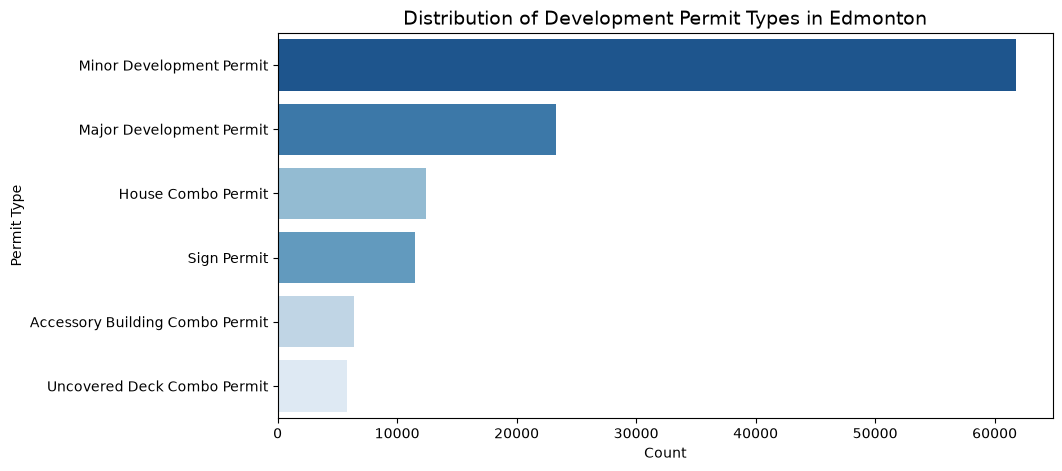

In [69]:
plt.figure(figsize=(10, 5))
sb.countplot(data=df,
 y='Permit Type', 
 hue='Permit Type',
 legend=False,
 order=df['Permit Type'].value_counts().index, 
 palette='Blues_r')
plt.xlabel('Count', fontsize=10)
plt.title('Distribution of Development Permit Types in Edmonton', fontsize=14)
plt.show()

Explanation: This horizontal bar chart visualizes the frequency distribution
across all Edmonton development permit categories. It clearly emphasizes how 
Minor Development Permits dominate the municipal workload.

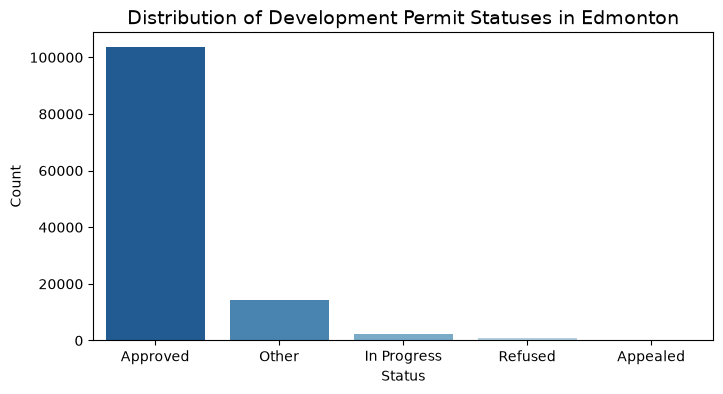

In [70]:
plt.figure(figsize=(8,4))
status_order = df['Status'].value_counts().index
sb.countplot(data=df, 
x='Status', 
hue='Status',
order=status_order,
hue_order=status_order, # The bars were being coloured out of order and this fixes it.
legend=False,
palette='Blues_r')
plt.ylabel('Count', fontsize=10)
plt.title('Distribution of Development Permit Statuses in Edmonton', fontsize=14)
plt.show()

Explanation: This count plot displays the outcome status of development permits.
We show that the vast majority of permit requests that are submitted receive
an Approved status.

<!-- Explanation: This count plot displays the outcome status of development permits.
It clearly illustrates the overwhelming majority of permits that are submitted 
reach the Approved status. The rest of the statuses are almost negligible in 
comparison -->

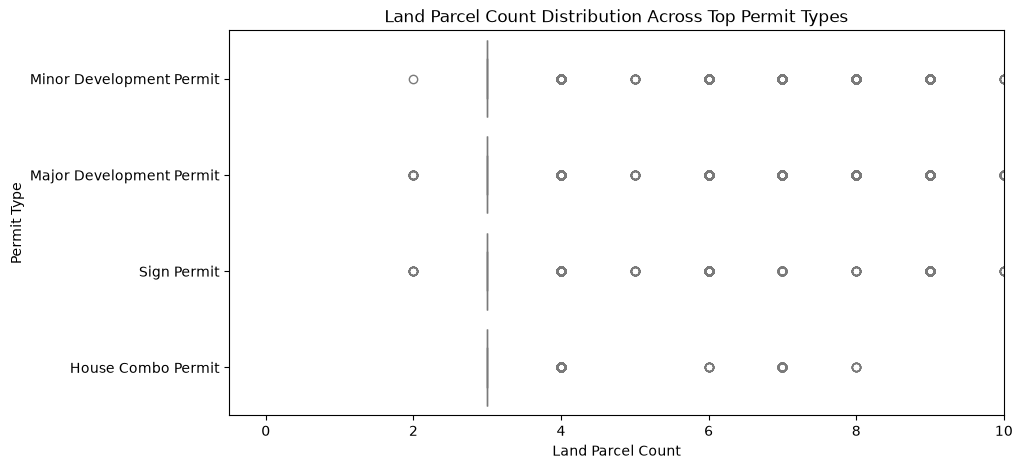

In [71]:
plt.figure(figsize=(10,5))
# Find and store the top 4 types of permits
top_types = df['Permit Type'].value_counts().index[:4]
filtered_df = df[df['Permit Type'].isin(top_types)]

sb.boxplot(data=filtered_df, x='Land Parcel Count', y='Permit Type', hue='Permit Type', legend=False, palette='Pastel1')
plt.title('Land Parcel Count Distribution Across Top Permit Types')
plt.xlim(-0.5, 10) # Truncating chart to contain 98.5% of all records focusing
                   # focusing the user to the most relevant portion of the
                   # dataset.
plt.show()

Explanation: This plot illustrates the median and IQR spread of Land Parcel
Count across different permit types. We can see that most development classes
center right around 1 to 3 parcels. This represents the majority residential and
commercial lot scales in Edmonton's municipal planning.

Reflection:
What worked well: Seaborn integrates seamlessly with Pandas. Using 
sb.countplot() and sb.boxplot() let me do complex categorical breakdowns
cleanly without needing manual aggregation loops. I also like the automatic
axis labels. I did need to specify the count labels because they were not
properly capitalized

Challenge encountered and how it was addressed: I set the palette to be
but was getting a notice to set the hue as in the future it will be required.
When I did that the colouring order of the columns was thrown off where the
first column of chart 2 was lighter than the second and third. This was
confusing and required me to explicitly call hue_order to have all the columns
be coloured in a representative manner. 

What I learned about the new library: I learned how Seaborn handles automatic
palette mapping, groups the categorical data efficiently, and simplifies 
statistical graphic styling vs base Matplotlib.

Resources and methods used to learn: I read through the official Seaborn
documentation and tutorials, on top of that I experimented in this Jupyter 
Notebook